# DL_T14_2D — Sentiment analysis of code-mixed Telugu–English mobile-network complaints
Task 2, Team 14 (MGIT, CM701PC/CM751PC). **Data is synthetic** (see `data/DATA_CARD.md`).

This notebook (1) inspects the data, (2) runs a quick seeded comparison of SimpleRNN / LSTM / GRU, and (3) displays the full results produced by `python src/experiments.py` (3 seeds × 8 configurations, sequence-length sweep, gradient profile, error analysis).

In [1]:
import sys, os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))
from common import *
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

I0000 00:00:1793252904.615970   17326 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793252906.065917   17326 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Data

In [2]:
df = load_data()
print(df.groupby(['split','label']).size().unstack())
print(df.groupby('label').n_tokens.describe().round(1))
df[['text','label','category']].sample(6, random_state=1)

label  mixed  negative  positive
split                           
test     150       150       150
train    700       700       700
val      150       150       150
           count  mean   std   min   25%   50%   75%   max
label                                                     
mixed     1000.0  38.0  16.7  10.0  23.0  38.0  50.0  83.0
negative  1000.0  21.0  17.4   2.0   7.0  14.0  31.0  69.0
positive  1000.0  20.8  17.3   4.0   8.0  11.0  31.2  69.0


,text,label,category
1957,"Nijam ga validity extend avvadam sulabham ga undi sir. maa intlo andaru same network vadataru. naa phone android 12,...",mixed,mixed_distant
2087,"Namaskaram sir. Sir, meeku oka vishayam cheppali. Good morning sir, mee service gurinchi manchiga vinnanu. tower ran...",positive,polite_opening
1394,"Good morning sir, mee service gurinchi manchiga vinnanu. honestly calls ventane connect avtunnayi, inkoka vishayam a...",mixed,polite_opening
1520,nijam ga SIM activation 3 rojulu pattindi.,negative,plain
1098,Hello customer care team. Nenu last 3 years nundi mee SIM vadutunna. Prepaid plan 299 vadutunna every month. Nenu Hy...,mixed,long_buried
393,ippudu roaming lo network asalu pani cheyyaledu sir.,negative,plain


## 2. Quick run (seed 0, max length 64, keep last tokens) — three recurrent layers trained from scratch

In [3]:
vocab = build_vocab(df[df.split=='train'].tokens)
print('vocab size', len(vocab))
S = {s: (encode(df[df.split==s].tokens.tolist(), vocab, 64, 'pre'), df[df.split==s].y.values) for s in ['train','val','test']}
rows = []
for name in LAYERS:
    set_seed(0)
    m = build_model(name, len(vocab)+2)
    fit(m, *S['train'], *S['val'])
    p = predict(m, S['test'][0])
    rows.append({'layer': name, 'test_macro_f1': macro_f1(S['test'][1], p), 'f1_mixed': per_class_f1(S['test'][1], p)[2],
                 'sec_per_10k': time_10k(m, S['test'][0]), 'params': m.count_params()})
pd.DataFrame(rows).round(3)

vocab size 746


E0000 00:00:1793252908.939370   17326 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


,layer,test_macro_f1,f1_mixed,sec_per_10k,params
0,SimpleRNN,0.827,0.993,0.519,56323
1,LSTM,0.798,0.993,1.011,81091
2,GRU,0.778,0.881,0.730,73027


## 3. Full results (3 seeds each; produced by `src/experiments.py`)
### Sequence length / truncation sweep (LSTM, validation macro-F1)

,truncate,maxlen,val_f1,val_sd,sec_10k
0,post,16,0.638,0.018,0.297
1,post,32,0.706,0.021,0.494
2,post,64,0.846,0.015,0.857
3,post,128,0.850,0.002,1.764
4,pre,16,0.847,0.006,0.290
5,pre,32,0.850,0.009,0.487
6,pre,64,0.854,0.008,0.896
7,pre,128,0.850,0.002,1.608


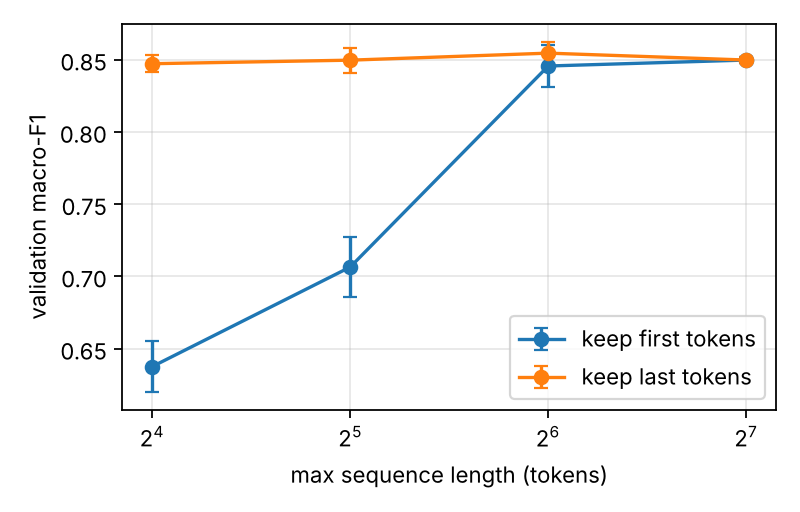

In [4]:
display(pd.read_csv('results/seqlen_sweep_summary.csv').round(3))
display(Image('figures/seqlen_sweep.png', width=420))

### Three recurrent layers × two training strategies

In [5]:
t = pd.read_csv('results/comparison_table.csv')
t[['layer','strategy','val_macro_f1_mean','test_macro_f1_mean','test_macro_f1_std','test_f1_mixed_mean','sec_per_10k_mean','params_first']].round(3)

,layer,strategy,val_macro_f1_mean,test_macro_f1_mean,test_macro_f1_std,test_f1_mixed_mean,sec_per_10k_mean,params_first
0,BiGRU,scratch,0.866,0.832,0.020,0.983,0.871,98179
1,BiLSTM,scratch,0.839,0.791,0.022,0.979,1.144,114307
2,GRU,imdb,0.855,0.813,0.027,0.956,0.820,73027
3,GRU,scratch,0.832,0.775,0.013,0.926,0.825,73027
4,LSTM,imdb,0.849,0.814,0.008,0.968,0.981,81091
5,LSTM,scratch,0.854,0.818,0.018,0.998,0.916,81091
6,SimpleRNN,imdb,0.863,0.834,0.014,0.980,0.459,56323
7,SimpleRNN,scratch,0.866,0.830,0.011,0.985,0.470,56323


### Gradient flow to early tokens (vanishing-gradient evidence)

,SimpleRNN,LSTM,GRU
tokens_before_end,,,
0,0.224130,0.207785,0.189096
10,0.258920,0.182953,0.177535
20,0.095997,0.036997,0.025621
40,0.013063,0.009720,0.000431
59,0.001380,0.001210,0.000014


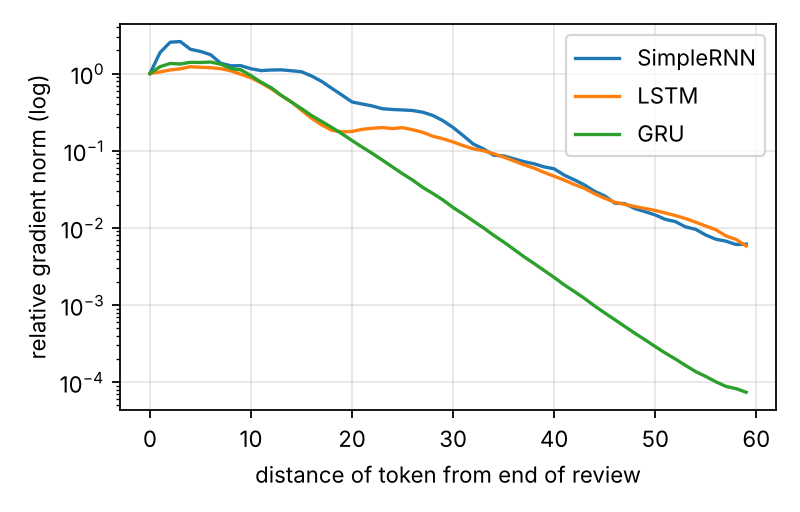

In [6]:
g = pd.read_csv('results/gradient_profile.csv', index_col=0)
display(g.iloc[[0,10,20,40,59]])
display(Image('figures/gradient_profile.png', width=420))

### Best model on the test split

best config (by mean validation macro-F1): ('SimpleRNN', 'scratch'), seed 1

              precision    recall  f1-score   support

    negative      0.782     0.740     0.760       150
    positive      0.753     0.793     0.773       150
       mixed      0.993     0.993     0.993       150

    accuracy                          0.842       450
   macro avg      0.843     0.842     0.842       450
weighted avg      0.843     0.842     0.842       450

{
  "best": [
    "SimpleRNN",
    "scratch"
  ],
  "seed": 1,
  "maxlen": 64,
  "test_macro_f1": 0.8421115262211152,
  "f1_per_class": {
    "negative": 0.7602739726027398,
    "positive": 0.7727272727272727,
    "mixed": 0.9933333333333333
  },
  "cohen_kappa_model_vs_gold": 0.7633333333333333,
  "sec_per_10k_reviews": 0.5504794099999799,
  "params": 56323
}


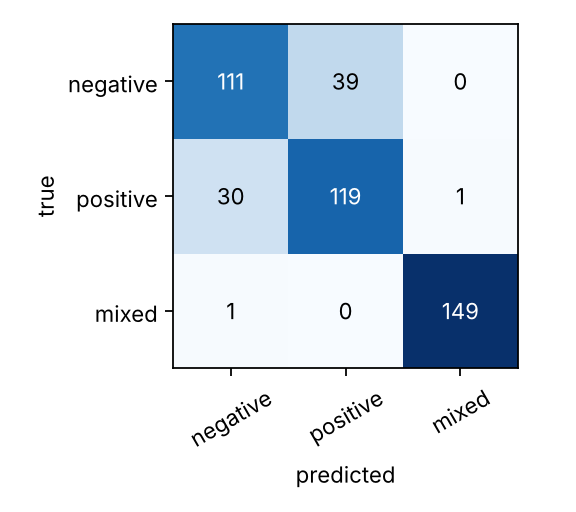

In [7]:
print(open('results/best_report.txt').read())
print(open('results/best_summary.json').read())
display(Image('figures/confusion_matrix.png', width=300))

### Error analysis

In [8]:
for c in ['phrase_pool','category','bucket','spelling_noise']:
    print(c); display(pd.read_csv(f'results/best_acc_by_{c}.csv').round(3))
pd.read_csv('results/best_errors.csv').sample(10, random_state=0)

phrase_pool


,phrase_pool,n,acc
0,seen,233,0.974
1,unseen,217,0.700


category


,category,n,acc
0,long_buried,100,0.870
1,mixed_distant,52,1.000
2,negation,50,0.660
3,plain,131,0.832
4,polite_opening,98,0.837
5,sarcasm,19,0.842


bucket


,bucket,n,acc
0,long(>40),120,0.908
1,medium(16-40),143,0.888
2,short(<=15),187,0.765


spelling_noise


,spelling_noise,n,acc
0,0,234,0.833
1,1,216,0.852


,id,text,label,pred_label,category,spelling_noise,phrase_pool
26,921,"Hi team, kontha time teesukoni ee review rastunna. daily hills daggara kuda full bars vachayi andi. pls do the needful.",positive,negative,polite_opening,1,unseen
27,931,"Super network sir, thanks a lot, actually eppudu choosina service unstable ga untundi sir.",negative,positive,sarcasm,0,unseen
48,1677,"Good morning sir, mee service gurinchi manchiga vinnanu. nijam ga range vishayam lo mee service number one.",positive,negative,polite_opening,0,unseen
22,825,Hello customer care team. maa area lo konni rojula nundi construction jarugutondi. nenu hyderabad lo gandipet daggar...,positive,negative,long_buried,0,unseen
30,1083,Coverage okay ga ledu andi. please look into this.,negative,positive,negation,0,unseen
51,1921,daily coverage okay ga ledu sir. Regards.,negative,positive,negation,0,unseen
7,349,nijam ga recharg sulabham ga ledhu anna. Regards.,negative,positive,negation,1,unseen
59,2446,"First of all mee team ki thanks, chalaa respect vundhi. namaskaram sir, mee company ni nenu 5 years nundi nammutunna...",negative,positive,polite_opening,1,unseen
34,1249,"Sir, meeku oka vishayam cheppali. Dear sir/madam, mee brand ante naku chala ishtam. actually eppudu choosina service...",negative,positive,polite_opening,0,unseen
70,2976,monna nundi long calls kuda disconnect avvaledu really.,positive,negative,plain,0,unseen


To reproduce everything: `python src/generate_dataset.py && python src/pretrain_imdb.py && python src/experiments.py`.